In [1]:
import os
import cv2
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

In [2]:
def extract_skull(image):
    _, thresh = cv2.threshold(image, 1, 255, cv2.THRESH_BINARY)
    kernel = np.ones((3, 3), np.uint8)
    cleaned = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel)
    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(cleaned, connectivity=8)
    if num_labels < 2:
        return cleaned
    largest_label = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    return (labels == largest_label).astype(np.uint8) * 255

In [3]:
def process_split(split_name, base_input_dir, base_output_dir):
    input_dir = Path(base_input_dir) / split_name
    output_dir = Path(base_output_dir) / split_name
    os.makedirs(output_dir, exist_ok=True)

    for img_path in input_dir.glob("*.png"):
        image = cv2.imread(str(img_path), cv2.IMREAD_GRAYSCALE)
        if image is None:
            print(f"❌ Could not load: {img_path}")
            continue

        skull_mask = extract_skull(image)
        masked_image = np.where(skull_mask > 0, image, 0).astype(np.uint8)

        output_path = output_dir / img_path.name
        cv2.imwrite(str(output_path), masked_image)
        print(f"✅ Saved: {output_path}")

In [4]:
# === Run for train/val/test ===
input_base = "/kaggle/input/dataset/images"
output_base = "/kaggle/working/dataset/images"

for split in ["train", "val", "test"]:
    process_split(split, input_base, output_base)

✅ Saved: /kaggle/working/dataset/images/train/10_11.png
✅ Saved: /kaggle/working/dataset/images/train/KARIMI MAJID-638573343125897095_24.png
✅ Saved: /kaggle/working/dataset/images/train/10_1.png
✅ Saved: /kaggle/working/dataset/images/train/MOHAMMAD-638573317836215846_11.png
✅ Saved: /kaggle/working/dataset/images/train/VAKILI KAZEM-638573353637377316_29.png
✅ Saved: /kaggle/working/dataset/images/train/42_1.png
✅ Saved: /kaggle/working/dataset/images/train/HOSSEINI HOSSEIN-638573325912545166_15.png
✅ Saved: /kaggle/working/dataset/images/train/3_9.png
✅ Saved: /kaggle/working/dataset/images/train/HOSSEINI HOSSEIN-638573325912545166_29.png
✅ Saved: /kaggle/working/dataset/images/train/TARASH KHAMANEH YOUSEF-638573246256506145_11.png
✅ Saved: /kaggle/working/dataset/images/train/MAFAKHERI MONIRSADAT-638573285887556992_28.png
✅ Saved: /kaggle/working/dataset/images/train/NAEIMI MOHAMMADALI-638573318959392715_1.png
✅ Saved: /kaggle/working/dataset/images/train/7_10.png
✅ Saved: /kaggle/w

In [5]:
!cp -r /kaggle/input/dataset/labels /kaggle/working/dataset/labels

In [6]:
def visualize_yolo_obb(image_path, label_path):
    """
    Visualizes YOLOv8 OBB annotations on a given image.
    
    Args:
        image_path (str): Path to the image.
        label_path (str): Path to the corresponding YOLO OBB label file.
    """
    # Load image
    image = cv2.imread(image_path)
    if image is None:
        print(f"❌ Failed to load image: {image_path}")
        return
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    height, width = image.shape[:2]

    # Read label file
    if not os.path.exists(label_path):
        print(f"❌ Label file not found: {label_path}")
        return

    with open(label_path, 'r') as f:
        lines = f.readlines()

    # Draw OBBs
    for line in lines:
        parts = line.strip().split()
        if len(parts) != 9:
            continue
        class_id = int(parts[0])
        coords = np.array([float(p) for p in parts[1:]], dtype=np.float32).reshape(-1, 2)
        coords[:, 0] *= width
        coords[:, 1] *= height
        coords = coords.astype(np.int32)

        cv2.polylines(image, [coords], isClosed=True, color=(255, 0, 0), thickness=2)
        cx = int(coords[:, 0].mean())
        cy = int(coords[:, 1].mean())
        cv2.putText(image, str(class_id), (cx, cy), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 0), 2)

    # Show image
    plt.figure(figsize=(6, 6))
    plt.imshow(image)
    plt.axis("off")
    plt.title(f"{os.path.basename(image_path)}")
    plt.savefig(f"/kaggle/working/samples/{os.path.basename(image_path)}")
    plt.show()

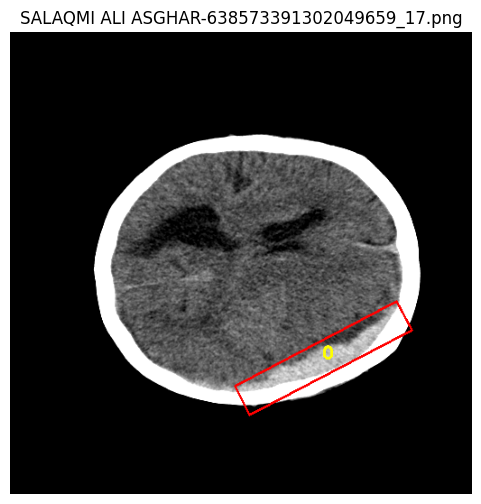

In [7]:
os.makedirs("/kaggle/working/samples", exist_ok=True)
visualize_yolo_obb(
    image_path="/kaggle/working/dataset/images/test/SALAQMI ALI ASGHAR-638573391302049659_17.png",
    label_path="/kaggle/working/dataset/labels/test/SALAQMI ALI ASGHAR-638573391302049659_17.txt"
)

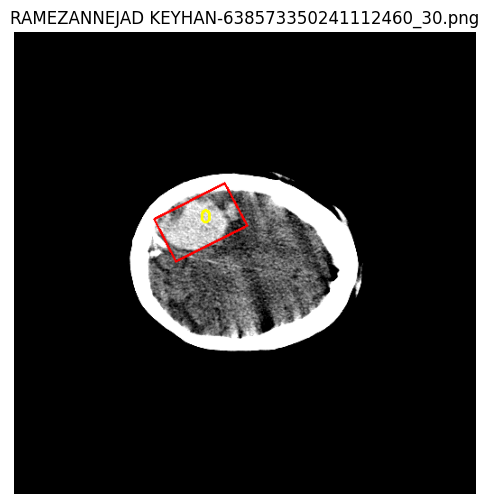

In [8]:
visualize_yolo_obb(
    image_path="/kaggle/working/dataset/images/test/RAMEZANNEJAD KEYHAN-638573350241112460_30.png",
    label_path="/kaggle/working/dataset/labels/test/RAMEZANNEJAD KEYHAN-638573350241112460_30.txt"
)

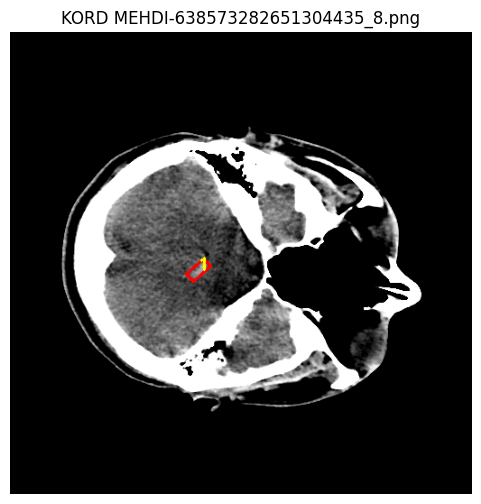

In [9]:
visualize_yolo_obb(
    image_path="/kaggle/working/dataset/images/test/KORD MEHDI-638573282651304435_8.png",
    label_path="/kaggle/working/dataset/labels/test/KORD MEHDI-638573282651304435_8.txt"
)

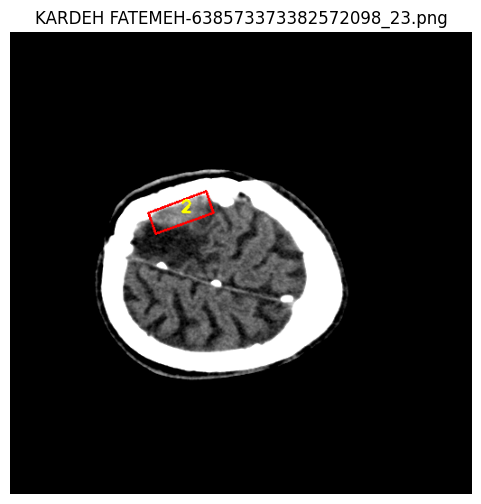

In [10]:
visualize_yolo_obb(
    image_path="/kaggle/working/dataset/images/test/KARDEH FATEMEH-638573373382572098_23.png",
    label_path="/kaggle/working/dataset/labels/test/KARDEH FATEMEH-638573373382572098_23.txt"
)